# TerminalBench 2.1 Luna v2 semantic clustering

This notebook analyses the open-coded design-decision events produced by the second Luna extraction run. It performs two parallel semantic-clustering experiments:

1. **Decision label + decision summary**
2. **Decision label only**

The notebook does not generate new labels and does not provide an existing taxonomy to the embedding or clustering stages. It only analyses the completed free-text output.


## Method

The completed decision events are embedded with `qwen3-embedding:0.6b` through Ollama's embedding endpoint. The vectors are L2-normalized and clustered in the complete semantic space.

Candidate solutions from k = 5 to k = 20 are evaluated with inertia and cosine silhouette score. The k = 8, 9, and 10 solutions are retained as a focused comparison with the earlier experiment and visualized with PCA, t-SNE, and UMAP. The projections display cluster assignments but do not determine them.


In [14]:
from __future__ import annotations

import hashlib
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import umap.umap_ as umap
from IPython.display import display
from matplotlib.colors import BoundaryNorm, ListedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

pd.set_option('display.max_colwidth', 140)
pd.set_option('display.max_rows', 120)
plt.style.use('seaborn-v0_8-whitegrid')
print('Imports complete.')

Imports complete.


## Configuration

Ollama is needed only when a matching embedding cache is unavailable. The configured embedding model can be installed with `ollama pull qwen3-embedding:0.6b`. All generated files are stored beside the Luna v2 extraction output.


In [15]:
SEED = 42
MIN_K = 5
MAX_K = 20
FOCUS_K = (8, 9, 10)

OLLAMA_BASE_URL = os.getenv('OLLAMA_BASE_URL', 'http://localhost:11434').rstrip('/')
EMBEDDING_MODEL = 'qwen3-embedding:0.6b'
EMBEDDING_BATCH_SIZE = 64
EMBEDDING_TIMEOUT_SECONDS = 1_800

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'outputs').exists():
            return candidate
        nested_project = candidate / 'design-decisions-by-LLMs'
        if (nested_project / 'pyproject.toml').exists() and (nested_project / 'outputs').exists():
            return nested_project
    raise FileNotFoundError('Run this notebook from inside the design-decisions-by-LLMs project.')

PROJECT_ROOT = find_project_root(Path.cwd())
INPUT_DIR = PROJECT_ROOT / 'outputs' / 'gpt_luna_light_v2'
INPUT_PATH = INPUT_DIR / 'decision_events.csv'
COMPLETED_PATH = INPUT_DIR / 'completed_trajectory_index.csv'
FAILED_PATH = INPUT_DIR / 'failed_trajectory_index.csv'
OUTPUT_DIR = INPUT_DIR / 'semantic_clustering'
FIGURE_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print('Input:', INPUT_PATH)
print('Outputs:', OUTPUT_DIR)


Input: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\gpt_luna_light_v2\decision_events.csv
Outputs: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\gpt_luna_light_v2\semantic_clustering


## Load and audit the completed decision events

Every row represents one extracted decision event. The audit checks coverage, evidence-boundary size, visibility, and label reuse before any embeddings are created. Original labels are preserved; a lowercase whitespace-normalized copy is used for semantic analysis.


In [16]:
REQUIRED_COLUMNS = {
    'trajectory_id', 'task_id', 'model', 'harness', 'decision_number',
    'source_steps', 'decision_summary', 'decision_type_label', 'visibility',
}

decisions_df = pd.read_csv(INPUT_PATH, keep_default_na=False)
completed_df = pd.read_csv(COMPLETED_PATH, keep_default_na=False)
failed_df = pd.read_csv(FAILED_PATH, keep_default_na=False)

missing_columns = REQUIRED_COLUMNS - set(decisions_df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

def clean_text(value: str) -> str:
    return re.sub(r'\s+', ' ', str(value or '')).strip()

def normalize_label(value: str) -> str:
    value = clean_text(value).lower().replace('_', ' ').replace('-', ' ')
    return re.sub(r'\s+', ' ', value).strip()

def source_step_count(value: str) -> int:
    return len([part for part in str(value).split(';') if part.strip()])

decisions_df = decisions_df.copy()
decisions_df['decision_type_label'] = decisions_df['decision_type_label'].map(clean_text)
decisions_df['decision_summary'] = decisions_df['decision_summary'].map(clean_text)
decisions_df['decision_type_label_normalized'] = decisions_df['decision_type_label'].map(normalize_label)
decisions_df['source_step_count'] = decisions_df['source_steps'].map(source_step_count)

blank_mask = decisions_df['decision_type_label_normalized'].eq('')
if blank_mask.any():
    print(f'Dropping {int(blank_mask.sum())} rows with an empty decision label.')
    decisions_df = decisions_df.loc[~blank_mask].copy()

events_per_trajectory = decisions_df.groupby('trajectory_id').size()
reused_boundaries = decisions_df.groupby(['trajectory_id', 'source_steps']).size()
reused_boundary_events = int(reused_boundaries.loc[reused_boundaries.gt(1)].sum())

audit = pd.Series({
    'completed trajectories': len(completed_df),
    'failed trajectories': len(failed_df),
    'decision events': len(decisions_df),
    'trajectories with decisions': decisions_df['trajectory_id'].nunique(),
    'mean decisions per trajectory': round(events_per_trajectory.mean(), 2),
    'median decisions per trajectory': float(events_per_trajectory.median()),
    'tasks': decisions_df['task_id'].nunique(),
    'models': decisions_df['model'].nunique(),
    'harnesses (non-empty)': decisions_df.loc[decisions_df['harness'].ne(''), 'harness'].nunique(),
    'unique normalized labels': decisions_df['decision_type_label_normalized'].nunique(),
    'median source steps per event': float(decisions_df['source_step_count'].median()),
    'events using more than 10 source steps': int(decisions_df['source_step_count'].gt(10).sum()),
    'events sharing a boundary with another event': reused_boundary_events,
})
display(audit.to_frame('value'))

display(
    decisions_df['visibility'].value_counts(dropna=False)
    .rename_axis('visibility').to_frame('events')
)
display(
    events_per_trajectory.value_counts().sort_index()
    .rename_axis('decisions_per_trajectory').to_frame('trajectories')
)
display(
    decisions_df['decision_type_label_normalized'].value_counts().head(25)
    .rename_axis('normalized_label').to_frame('events')
)
display(decisions_df.head(8))


,value
completed trajectories,350.00
failed trajectories,0.00
decision events,2157.00
trajectories with decisions,350.00
mean decisions per trajectory,6.16
median decisions per trajectory,6.00
tasks,87.00
models,17.00
harnesses (non-empty),6.00
unique normalized labels,1936.00


,events
visibility,
CONTEXTUAL,1218
EXPLICIT,939


,trajectories
decisions_per_trajectory,
1,7
2,12
3,32
4,40
5,65
6,60
7,49
8,24
9,23


,events
normalized_label,
task completion confirmation,12
task completion decision,10
verified task termination,10
validated task termination,9
successful task termination,7
end to end deployment validation,6
dependency installation,5
temporary artifact cleanup,4
output artifact verification,4


,trajectory_id,task_id,model,harness,decision_number,source_steps,decision_summary,decision_type_label,visibility,decision_type_label_normalized,source_step_count
0,tbench21:155af4cb-7f8b-5b73-930b-3a0bf6a7ddcb,terminal-bench/gpt2-codegolf,claude-fable-5,claude-code,1,3,"The agent chose to implement the model as a compact dependency-free C program that fits within the 5,000-byte constraint.",Implementation strategy,CONTEXTUAL,implementation strategy,1
1,tbench21:155af4cb-7f8b-5b73-930b-3a0bf6a7ddcb,terminal-bench/gpt2-codegolf,claude-fable-5,claude-code,2,3,The agent chose to read the checkpoint as a flat float array and access tensors through hard-coded offsets accounting for variable-name ...,Data layout handling,CONTEXTUAL,data layout handling,1
2,tbench21:155af4cb-7f8b-5b73-930b-3a0bf6a7ddcb,terminal-bench/gpt2-codegolf,claude-fable-5,claude-code,3,3,"The agent chose to reconstruct tokenization from vocab.bpe using byte-level vocabulary entries, merge ranks, and hash tables.",Input representation,CONTEXTUAL,input representation,1
3,tbench21:155af4cb-7f8b-5b73-930b-3a0bf6a7ddcb,terminal-bench/gpt2-codegolf,claude-fable-5,claude-code,4,3,The agent chose incremental causal inference with cached keys and values so generation avoids recomputing prior tokens.,Inference optimization,CONTEXTUAL,inference optimization,1
4,tbench21:155af4cb-7f8b-5b73-930b-3a0bf6a7ddcb,terminal-bench/gpt2-codegolf,claude-fable-5,claude-code,5,3,The agent chose arg-max selection for each generated token and streamed twenty tokens as output.,Output selection,CONTEXTUAL,output selection,1
5,tbench21:1cf6c212-cae9-5261-9770-8dc3f80fbf2f,terminal-bench/train-fasttext,claude-fable-5,claude-code,1,7;10;11,The agent installed a C++ compiler and build tools so the fastText dependency could be compiled after the initial package installation f...,Resolve dependency,EXPLICIT,resolve dependency,3
6,tbench21:1cf6c212-cae9-5261-9770-8dc3f80fbf2f,terminal-bench/train-fasttext,claude-fable-5,claude-code,2,14,"The agent converted parquet records into fastText text files using label prefixes, lowercasing, escaped-character cleanup, and punctuati...",Choose preprocessing,EXPLICIT,choose preprocessing,1
7,tbench21:1cf6c212-cae9-5261-9770-8dc3f80fbf2f,terminal-bench/train-fasttext,claude-fable-5,claude-code,3,16,"The agent established an initial supervised fastText configuration using 10-dimensional embeddings, word bigrams, five epochs, and a lar...",Set model configuration,EXPLICIT,set model configuration,1


## Create or load semantic embeddings

Two independent embedding caches are maintained. A fingerprint of the model and input text prevents stale vectors from being reused when the labels or summaries change. Label normalization changes only casing, underscores, hyphens, and repeated whitespace; it does not merge labels or introduce categories.


In [17]:
def require_ollama_embedding_model() -> list[str]:
    try:
        response = requests.get(f'{OLLAMA_BASE_URL}/api/tags', timeout=10)
        response.raise_for_status()
    except requests.RequestException as exc:
        raise RuntimeError(
            'Ollama is not reachable at http://localhost:11434. '
            'Start the Ollama desktop application or run `ollama serve`, then rerun this cell.'
        ) from exc

    available_models = sorted(
        model.get('name', '') for model in response.json().get('models', [])
    )
    if EMBEDDING_MODEL not in available_models:
        raise RuntimeError(
            f'Embedding model {EMBEDDING_MODEL!r} is not installed. '
            f'Run `ollama pull {EMBEDDING_MODEL}` and rerun this cell. '
            f'Available models: {available_models}'
        )
    return available_models

def embed_texts_with_cache(texts, cache_stem):
    texts = [clean_text(text) for text in texts]
    fingerprint_source = EMBEDDING_MODEL + '\n' + '\n'.join(texts)
    fingerprint = hashlib.sha256(fingerprint_source.encode('utf-8')).hexdigest()
    embedding_path = OUTPUT_DIR / f'{cache_stem}.npy'
    manifest_path = OUTPUT_DIR / f'{cache_stem}_manifest.json'

    cached_manifest = None
    if embedding_path.exists() and manifest_path.exists():
        cached_manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    if cached_manifest and cached_manifest.get('fingerprint') == fingerprint:
        cached_embeddings = np.load(embedding_path)
        if len(cached_embeddings) == len(texts):
            print(f'Loaded {cache_stem}:', cached_embeddings.shape)
            return cached_embeddings

    require_ollama_embedding_model()
    batches = []
    for start in tqdm(range(0, len(texts), EMBEDDING_BATCH_SIZE), desc=f'Embedding {cache_stem}'):
        try:
            response = requests.post(
                f'{OLLAMA_BASE_URL}/api/embed',
                json={
                    'model': EMBEDDING_MODEL,
                    'input': texts[start:start + EMBEDDING_BATCH_SIZE],
                    'truncate': False,
                },
                timeout=EMBEDDING_TIMEOUT_SECONDS,
            )
            response.raise_for_status()
        except requests.RequestException as exc:
            raise RuntimeError(
                f'Embedding request failed for rows {start}–{min(start + EMBEDDING_BATCH_SIZE, len(texts)) - 1}.'
            ) from exc
        batch = np.asarray(response.json().get('embeddings', []), dtype=np.float32)
        if len(batch) != len(texts[start:start + EMBEDDING_BATCH_SIZE]):
            raise RuntimeError('The embedding endpoint returned an unexpected number of vectors.')
        batches.append(batch)

    embeddings = np.vstack(batches)
    if not np.isfinite(embeddings).all():
        raise ValueError('The embedding matrix contains non-finite values.')
    np.save(embedding_path, embeddings)
    manifest_path.write_text(
        json.dumps({
            'fingerprint': fingerprint,
            'embedding_model': EMBEDDING_MODEL,
            'n_events': len(texts),
            'dimensions': int(embeddings.shape[1]),
        }, indent=2),
        encoding='utf-8',
    )
    print(f'Saved {cache_stem}:', embeddings.shape)
    return embeddings

In [18]:
label_summary_texts = (
    'Represent this software-agent design decision for semantic clustering. '
    'Decision type: ' + decisions_df['decision_type_label_normalized']
    + '. Decision description: ' + decisions_df['decision_summary']
).tolist()
label_only_texts = (
    'Represent this software-agent design decision for semantic clustering. '
    'Decision type: ' + decisions_df['decision_type_label_normalized']
).tolist()

label_summary_embeddings = embed_texts_with_cache(
    label_summary_texts, 'label_summary_semantic_embeddings',
)
label_only_embeddings = embed_texts_with_cache(
    label_only_texts, 'label_only_semantic_embeddings',
)

X_label_summary = normalize(label_summary_embeddings)
X_label_only = normalize(label_only_embeddings)
REPRESENTATIONS = {
    'label_summary': {
        'title': 'Decision label + summary',
        'matrix': X_label_summary,
        'color': '#287d7a',
    },
    'label_only': {
        'title': 'Decision label only',
        'matrix': X_label_only,
        'color': '#6f4e9c',
    },
}

display(pd.DataFrame({
    'representation': [value['title'] for value in REPRESENTATIONS.values()],
    'events': [len(value['matrix']) for value in REPRESENTATIONS.values()],
    'dimensions': [value['matrix'].shape[1] for value in REPRESENTATIONS.values()],
}))


Loaded label_summary_semantic_embeddings: (2157, 1024)
Loaded label_only_semantic_embeddings: (2157, 1024)


,representation,events,dimensions
0,Decision label + summary,2157,1024
1,Decision label only,2157,1024


## Elbow and silhouette diagnostics

The same candidate values and random seed are used for both semantic representations. These diagnostics compare candidate partitions; they do not automatically define or name a final set of concepts.


In [19]:
def fit_candidate_models(X, representation_name):
    upper_k = min(MAX_K, len(X) - 1)
    candidate_k = list(range(MIN_K, upper_k + 1))
    if not set(FOCUS_K).issubset(candidate_k):
        raise ValueError('The dataset is too small for k = 8, 9, and 10.')
    models = {}
    rows = []
    for k in tqdm(candidate_k, desc=f'Clustering {representation_name}'):
        model = KMeans(n_clusters=k, random_state=SEED, n_init=50)
        labels = model.fit_predict(X)
        models[k] = model
        sizes = np.bincount(labels)
        rows.append({
            'representation': representation_name,
            'k': k,
            'inertia': float(model.inertia_),
            'silhouette_cosine': float(silhouette_score(X, labels, metric='cosine')),
            'smallest_cluster': int(sizes.min()),
            'largest_cluster': int(sizes.max()),
        })
    return models, pd.DataFrame(rows)

models_by_representation = {}
metric_frames = []
for representation_name, config in REPRESENTATIONS.items():
    models, metrics = fit_candidate_models(config['matrix'], representation_name)
    models_by_representation[representation_name] = models
    metric_frames.append(metrics)

metrics_df = pd.concat(metric_frames, ignore_index=True)
metrics_df.to_csv(OUTPUT_DIR / 'semantic_cluster_count_metrics.csv', index=False)
display(metrics_df)

Clustering label_only: 100%|██████████| 16/16 [03:33<00:00, 13.36s/it]


,representation,k,inertia,silhouette_cosine,smallest_cluster,largest_cluster
0,label_summary,5,454.047150,0.065314,294,617
1,label_summary,6,446.328491,0.065040,132,502
2,label_summary,7,438.858826,0.071096,125,480
3,label_summary,8,432.300323,0.079781,79,421
4,label_summary,9,426.968140,0.074227,107,461
5,label_summary,10,420.502197,0.081740,78,409
6,label_summary,11,415.609436,0.088655,51,383
7,label_summary,12,411.019012,0.089398,51,290
8,label_summary,13,406.893982,0.092687,46,278
9,label_summary,14,403.508148,0.091089,43,273


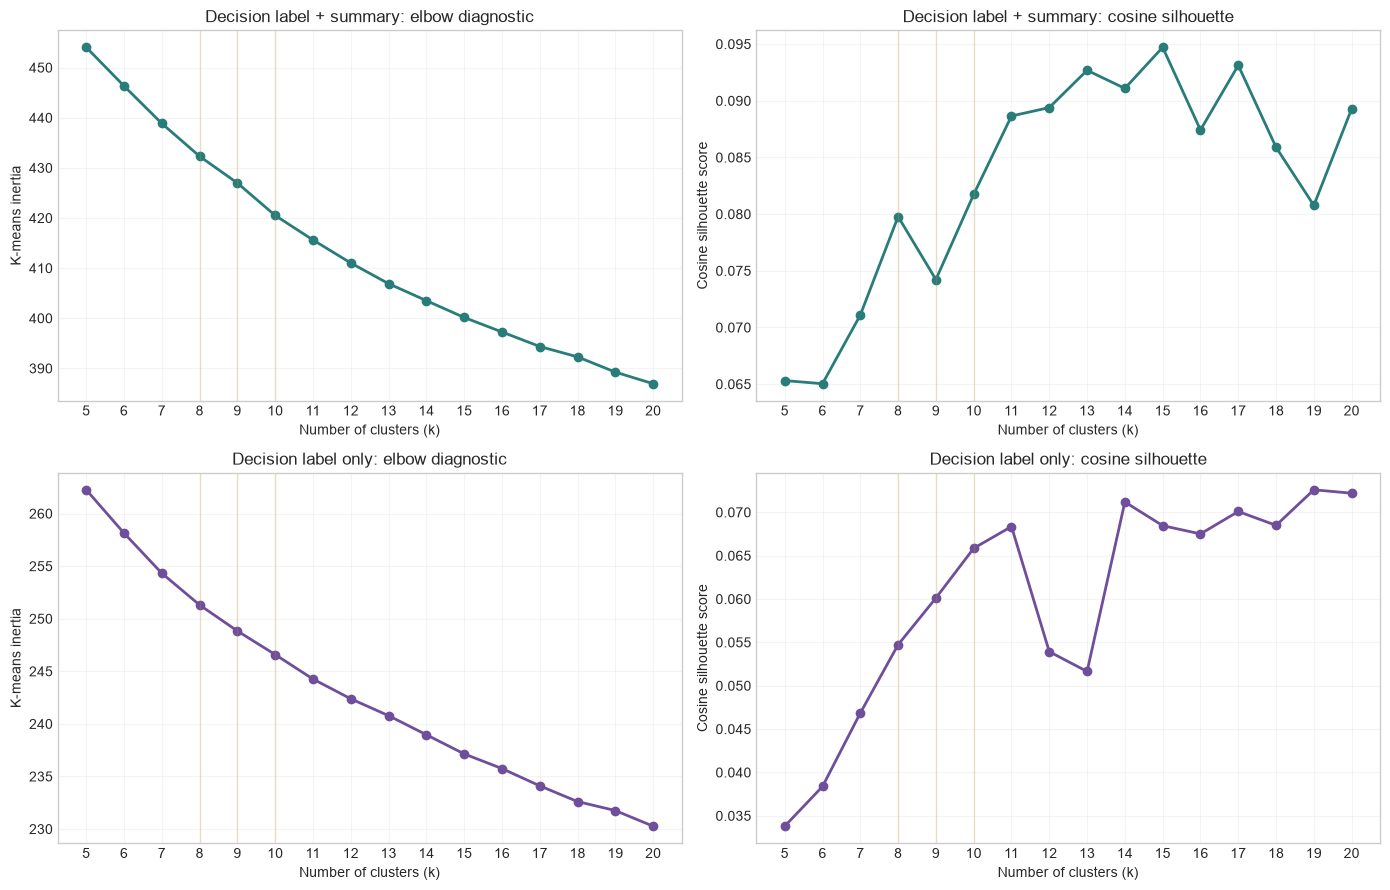

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (representation_name, config) in enumerate(REPRESENTATIONS.items()):
    subset = metrics_df.loc[metrics_df['representation'].eq(representation_name)]
    axes[row, 0].plot(subset['k'], subset['inertia'], marker='o', color=config['color'], linewidth=2)
    axes[row, 0].set_title(f"{config['title']}: elbow diagnostic")
    axes[row, 0].set_ylabel('K-means inertia')
    axes[row, 1].plot(
        subset['k'], subset['silhouette_cosine'], marker='o',
        color=config['color'], linewidth=2,
    )
    axes[row, 1].set_title(f"{config['title']}: cosine silhouette")
    axes[row, 1].set_ylabel('Cosine silhouette score')
    for ax in axes[row]:
        for k in FOCUS_K:
            ax.axvline(k, color='#c49a3a', alpha=.25, linewidth=1)
        ax.set_xlabel('Number of clusters (k)')
        ax.set_xticks(subset['k'])
        ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'semantic_elbow_and_silhouette.png', dpi=180, bbox_inches='tight')
plt.show()

## Focused comparison: k = 8, 9, and 10

Assignments for both semantic representations are stored together. Adjusted Rand Index measures how similarly the two input formulations partition the same events. The selected values provide a focused comparison rather than an assumption about the correct number of concepts.


In [21]:
assignments_df = decisions_df.copy()
agreement_rows = []
for representation_name in REPRESENTATIONS:
    for k in FOCUS_K:
        assignments_df[f'{representation_name}_cluster_k{k}'] = (
            models_by_representation[representation_name][k].labels_
        )
for k in FOCUS_K:
    agreement_rows.append({
        'k': k,
        'adjusted_rand_label_summary_vs_label_only': adjusted_rand_score(
            assignments_df[f'label_summary_cluster_k{k}'],
            assignments_df[f'label_only_cluster_k{k}'],
        ),
    })
agreement_df = pd.DataFrame(agreement_rows)
assignments_df.to_csv(OUTPUT_DIR / 'semantic_cluster_assignments_k8_k9_k10.csv', index=False)
agreement_df.to_csv(OUTPUT_DIR / 'semantic_representation_agreement.csv', index=False)
display(agreement_df)

,k,adjusted_rand_label_summary_vs_label_only
0,8,0.253728
1,9,0.275572
2,10,0.231283


In [22]:
def plot_single_projection(points, representation_name, method, k):
    title = REPRESENTATIONS[representation_name]['title']
    labels = models_by_representation[representation_name][k].labels_
    colors = list(plt.get_cmap('tab10').colors[:k])
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(-.5, k + .5, 1), cmap.N)

    fig, ax = plt.subplots(figsize=(11.5, 7.5))
    scatter = ax.scatter(
        points[:, 0], points[:, 1], c=labels, cmap=cmap, norm=norm,
        s=40, alpha=.78, linewidths=0,
    )
    ax.set_title(f'{title} — {method}, k = {k}', fontsize=16, pad=14)
    ax.set_xlabel(f'{method} dimension 1', fontsize=12)
    ax.set_ylabel(f'{method} dimension 2', fontsize=12)
    ax.grid(alpha=.14)
    colorbar = fig.colorbar(scatter, ax=ax, ticks=np.arange(k), fraction=.045, pad=.025)
    colorbar.set_label('K-means cluster')
    plt.tight_layout()

    filename = f'{representation_name}_{method.lower().replace("-", "")}_k{k}.png'
    plt.savefig(FIGURE_DIR / filename, dpi=200, bbox_inches='tight')
    plt.show()


In [23]:
PCA_POINTS = {}
for representation_name, config in REPRESENTATIONS.items():
    PCA_POINTS[representation_name] = PCA(
        n_components=2, random_state=SEED,
    ).fit_transform(config['matrix'])

print('PCA projections prepared.')


PCA projections prepared.


In [24]:
TSNE_POINTS = {}
for representation_name, config in REPRESENTATIONS.items():
    X = config['matrix']
    reduced_dimensions = min(50, X.shape[1], len(X) - 1)
    tsne_input = PCA(
        n_components=reduced_dimensions, random_state=SEED,
    ).fit_transform(X)
    perplexity = min(30, max(5, (len(X) - 1) // 3))
    TSNE_POINTS[representation_name] = TSNE(
        n_components=2, perplexity=perplexity, init='pca',
        learning_rate='auto', max_iter=1_000, random_state=SEED,
    ).fit_transform(tsne_input)

print('t-SNE projections prepared.')


t-SNE projections prepared.


In [25]:
UMAP_POINTS = {}
for representation_name, config in REPRESENTATIONS.items():
    X = config['matrix']
    UMAP_POINTS[representation_name] = umap.UMAP(
        n_components=2, n_neighbors=min(30, len(X) - 1), min_dist=.10,
        metric='cosine', random_state=SEED, n_jobs=1,
    ).fit_transform(X)

print('UMAP projections prepared.')


UMAP projections prepared.


## PCA cluster views

Each candidate cluster solution is displayed in a separate full-size output. The coordinates remain identical across k within the same representation, so the assignments can be compared directly.


### Decision label + summary


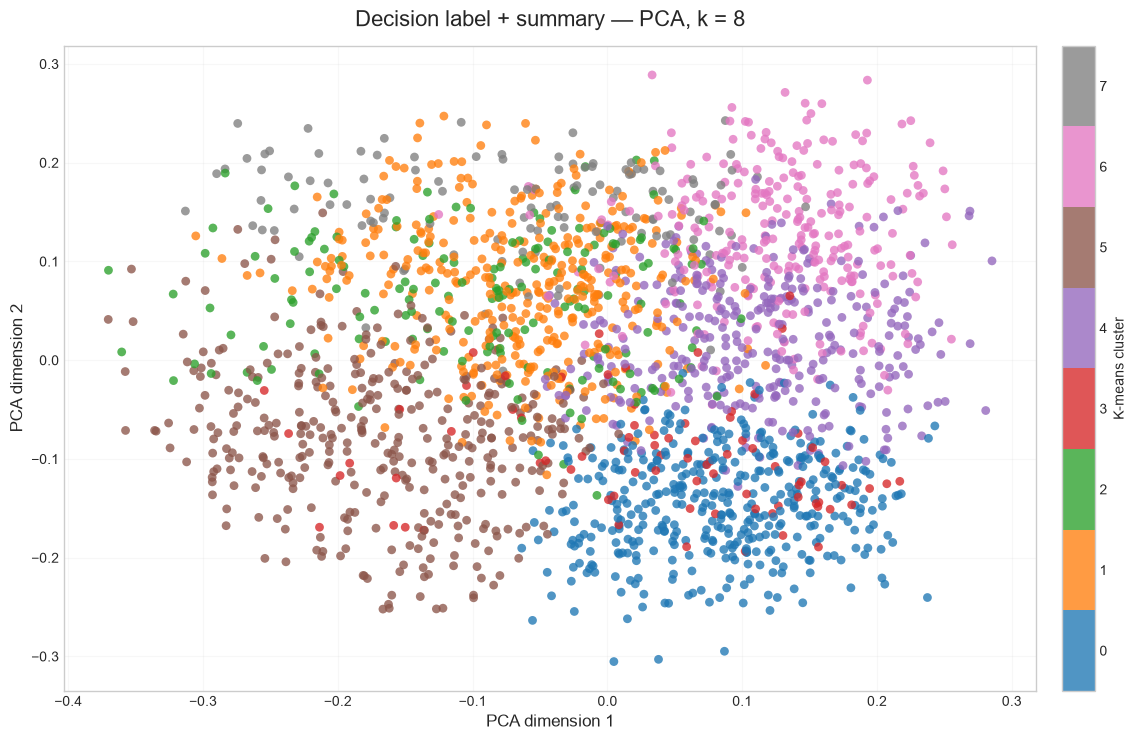

In [26]:
# Decision label + summary — PCA, k = 8
plot_single_projection(PCA_POINTS['label_summary'], 'label_summary', 'PCA', 8)


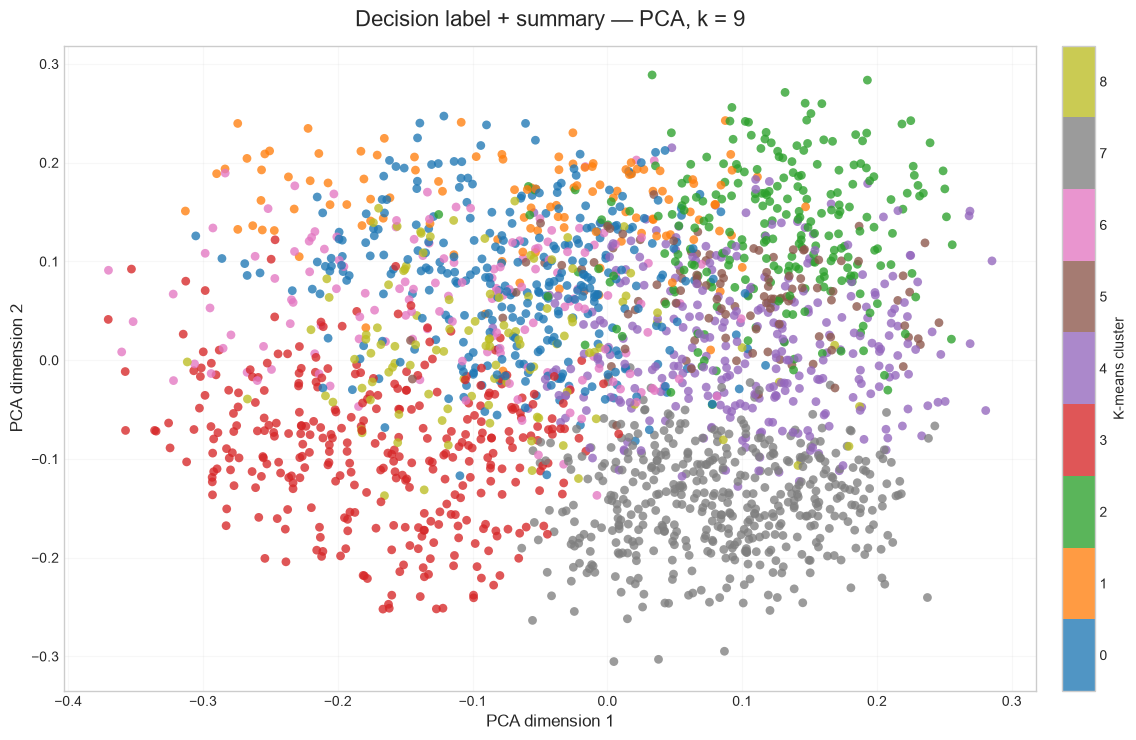

In [27]:
# Decision label + summary — PCA, k = 9
plot_single_projection(PCA_POINTS['label_summary'], 'label_summary', 'PCA', 9)


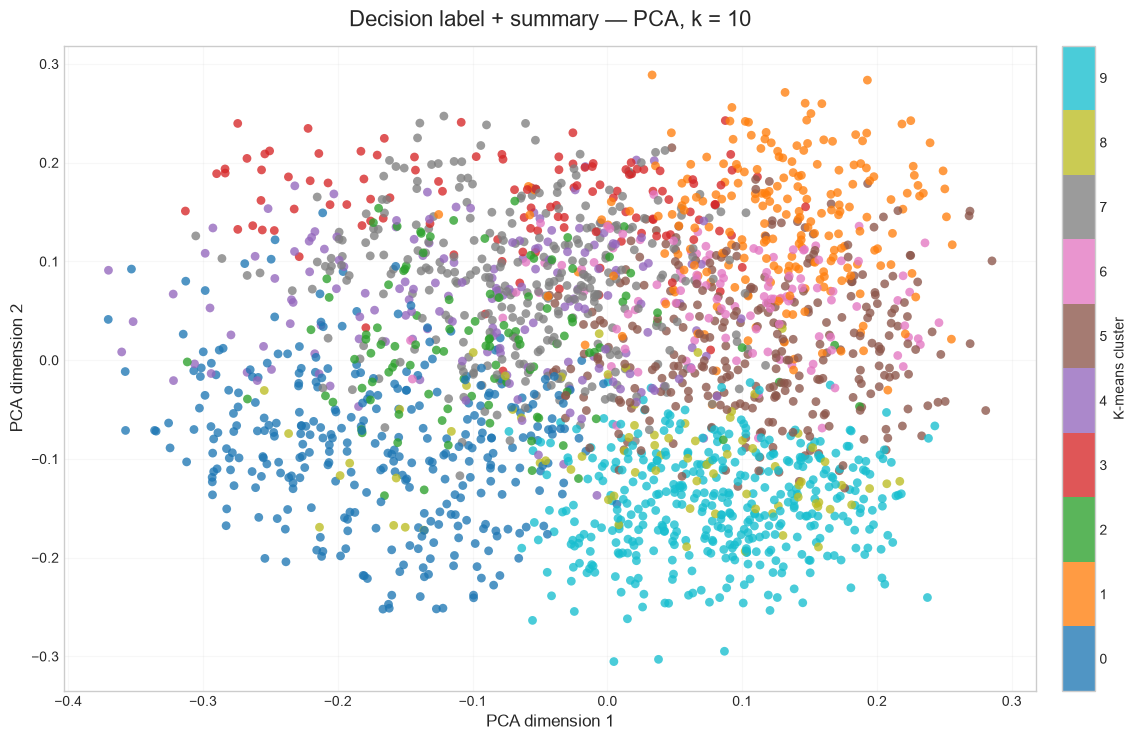

In [28]:
# Decision label + summary — PCA, k = 10
plot_single_projection(PCA_POINTS['label_summary'], 'label_summary', 'PCA', 10)


### Decision label only


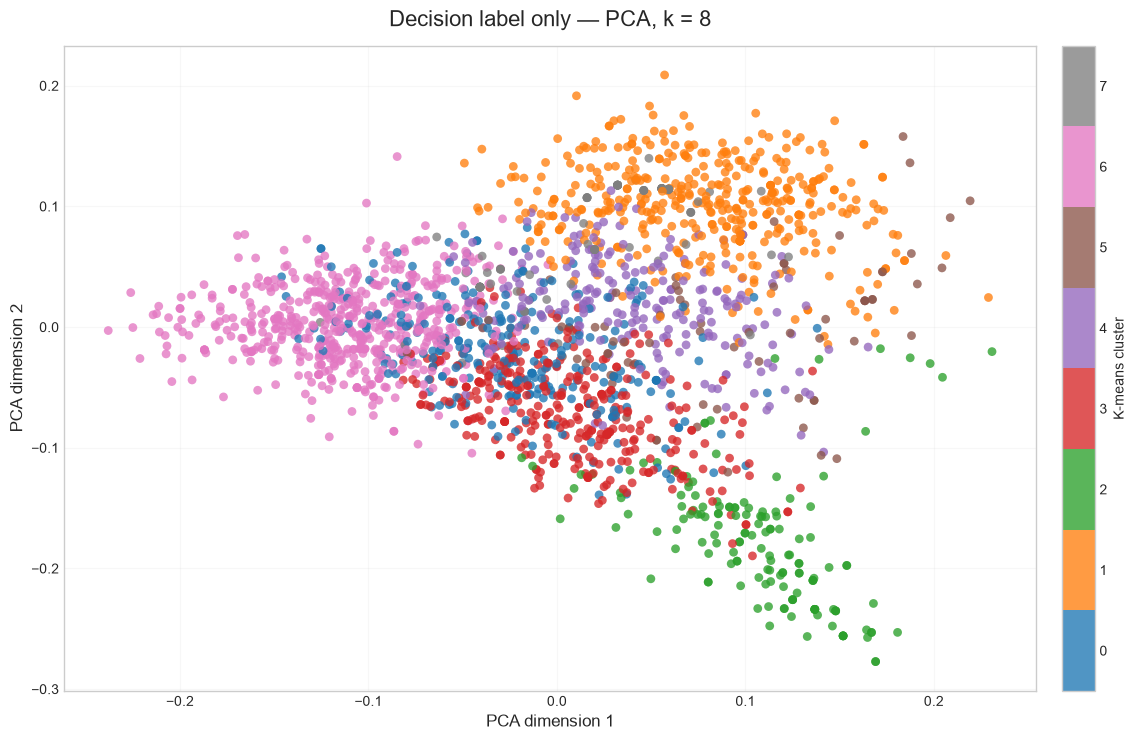

In [29]:
# Decision label only — PCA, k = 8
plot_single_projection(PCA_POINTS['label_only'], 'label_only', 'PCA', 8)


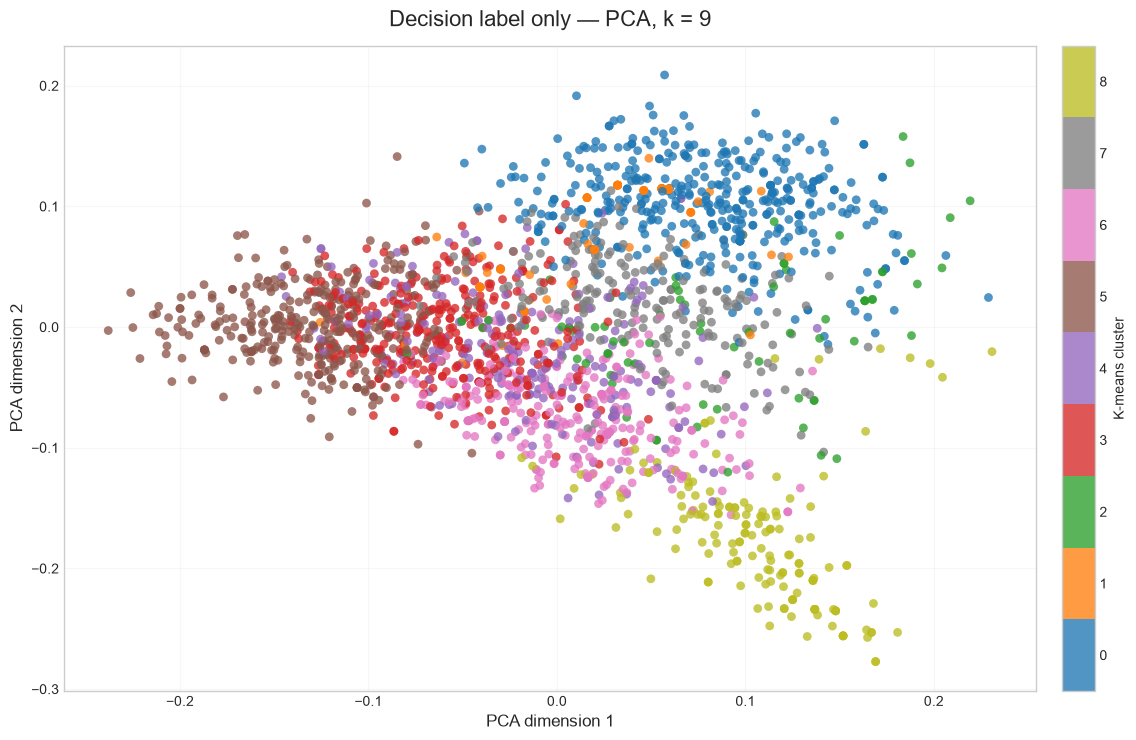

In [30]:
# Decision label only — PCA, k = 9
plot_single_projection(PCA_POINTS['label_only'], 'label_only', 'PCA', 9)


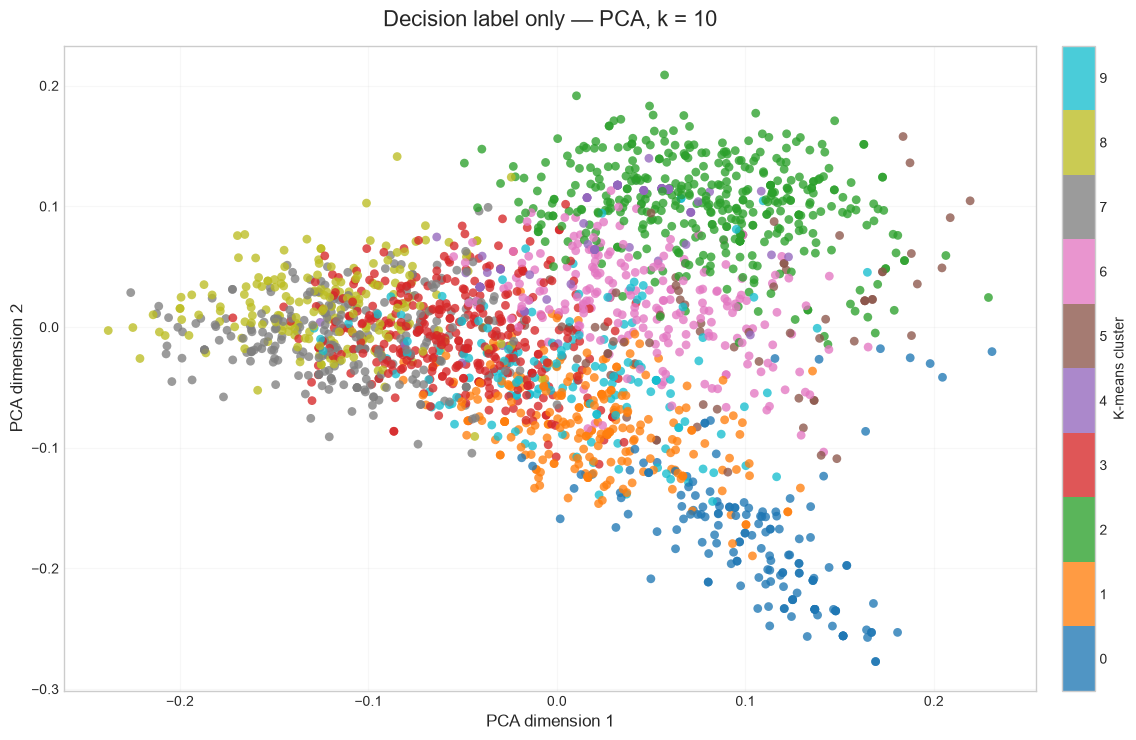

In [31]:
# Decision label only — PCA, k = 10
plot_single_projection(PCA_POINTS['label_only'], 'label_only', 'PCA', 10)


## t-SNE cluster views

Each candidate cluster solution is displayed in a separate full-size output. The coordinates remain identical across k within the same representation, so the assignments can be compared directly.


### Decision label + summary


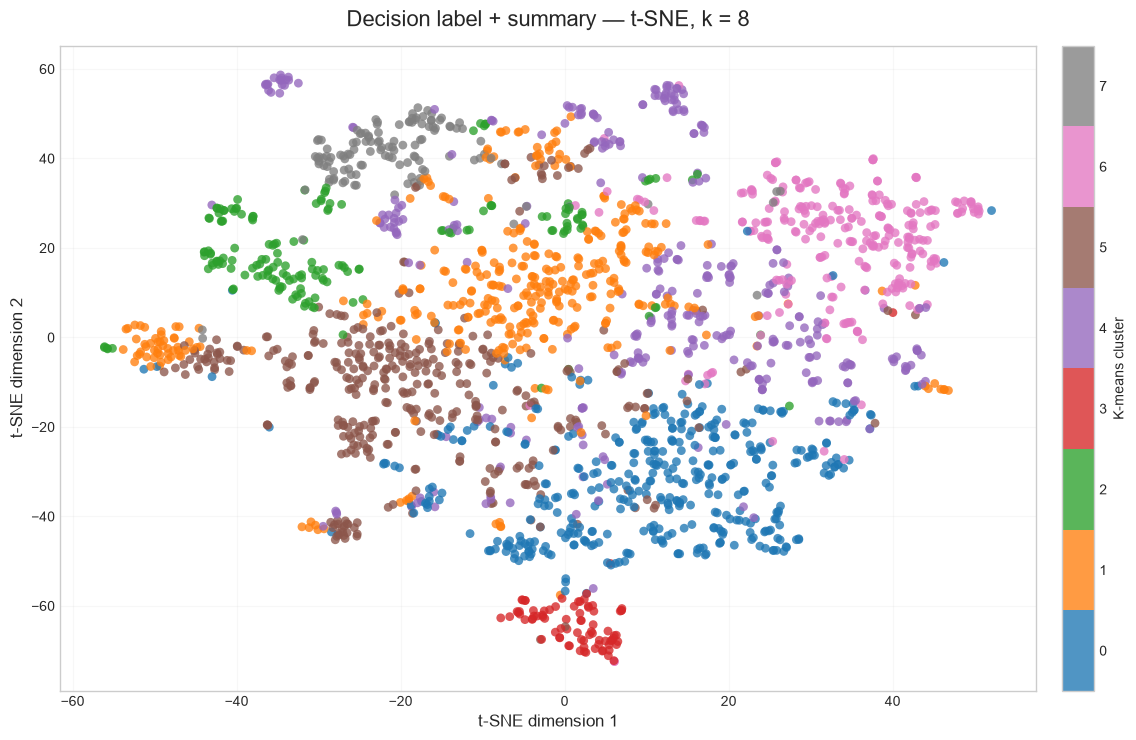

In [32]:
# Decision label + summary — t-SNE, k = 8
plot_single_projection(TSNE_POINTS['label_summary'], 'label_summary', 't-SNE', 8)


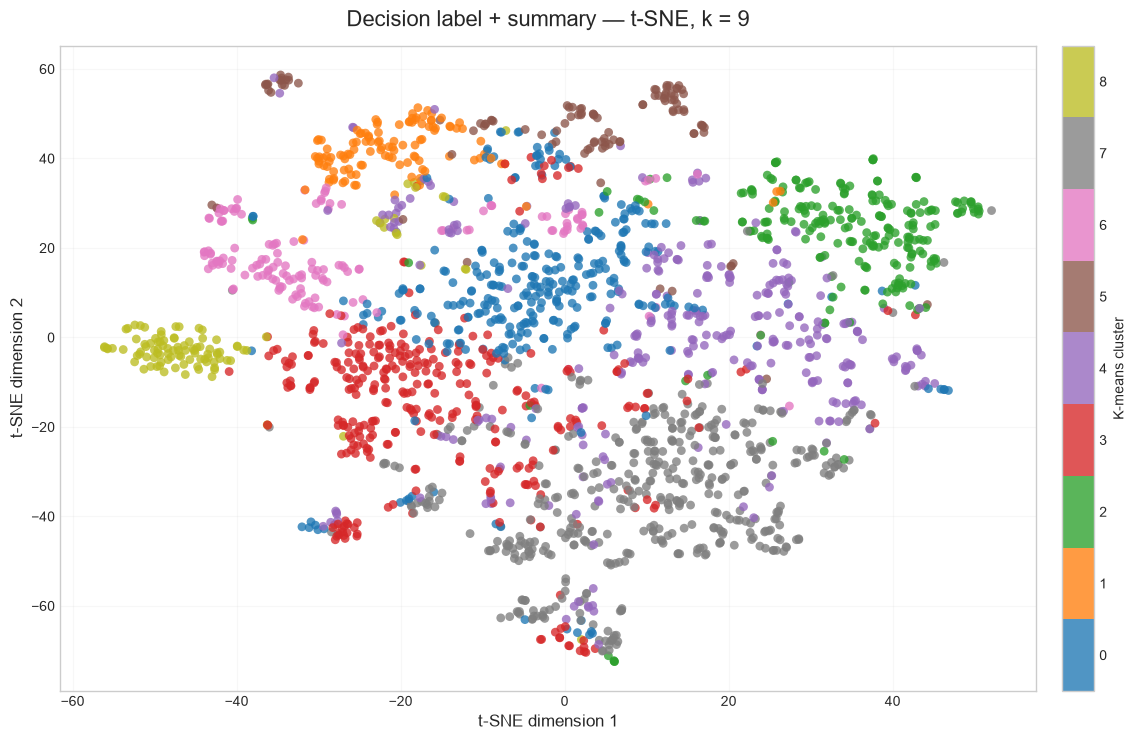

In [33]:
# Decision label + summary — t-SNE, k = 9
plot_single_projection(TSNE_POINTS['label_summary'], 'label_summary', 't-SNE', 9)


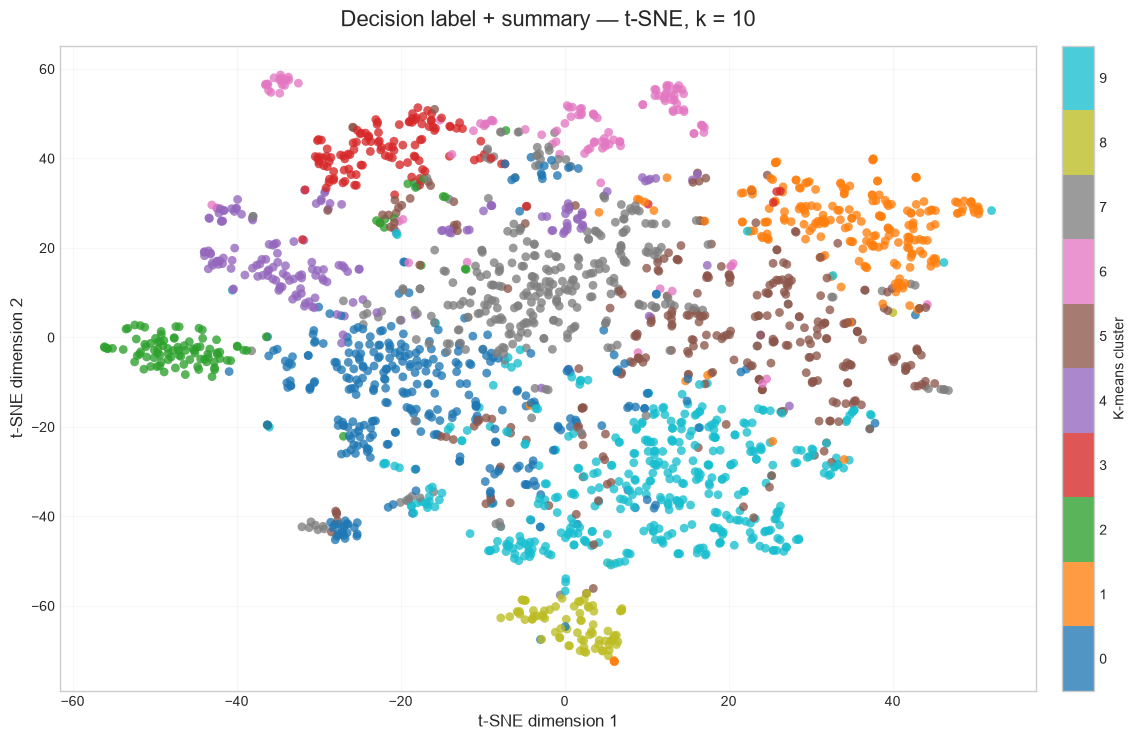

In [34]:
# Decision label + summary — t-SNE, k = 10
plot_single_projection(TSNE_POINTS['label_summary'], 'label_summary', 't-SNE', 10)


### Decision label only


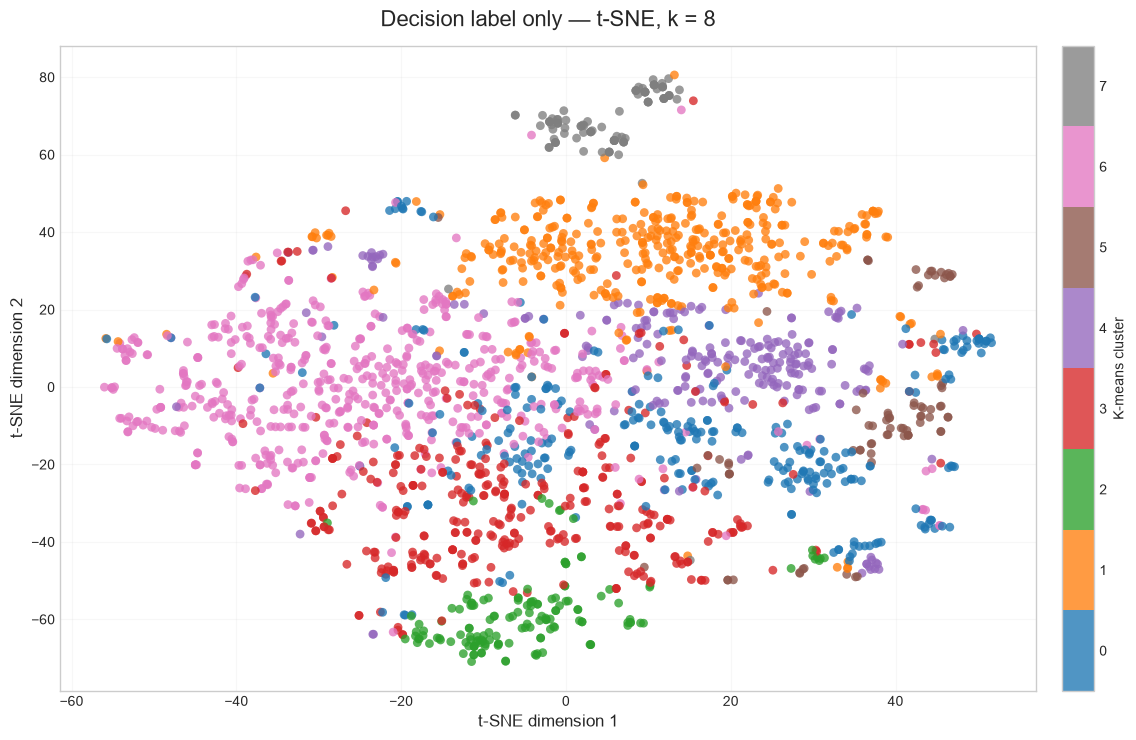

In [35]:
# Decision label only — t-SNE, k = 8
plot_single_projection(TSNE_POINTS['label_only'], 'label_only', 't-SNE', 8)


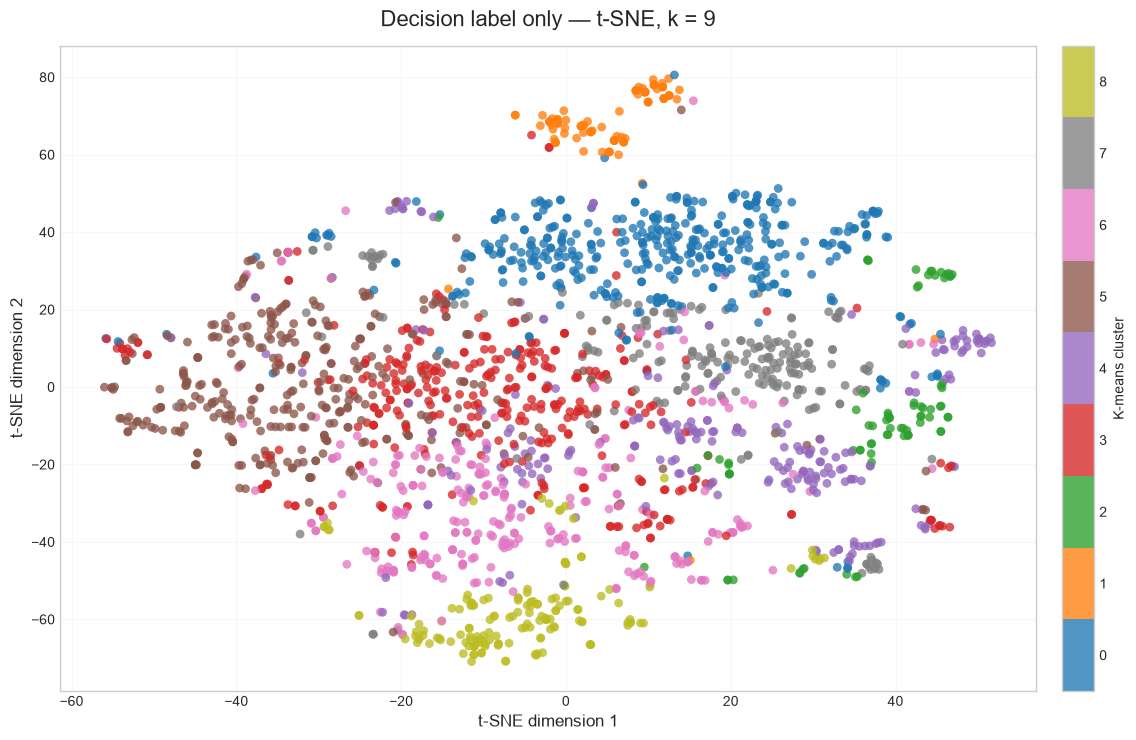

In [36]:
# Decision label only — t-SNE, k = 9
plot_single_projection(TSNE_POINTS['label_only'], 'label_only', 't-SNE', 9)


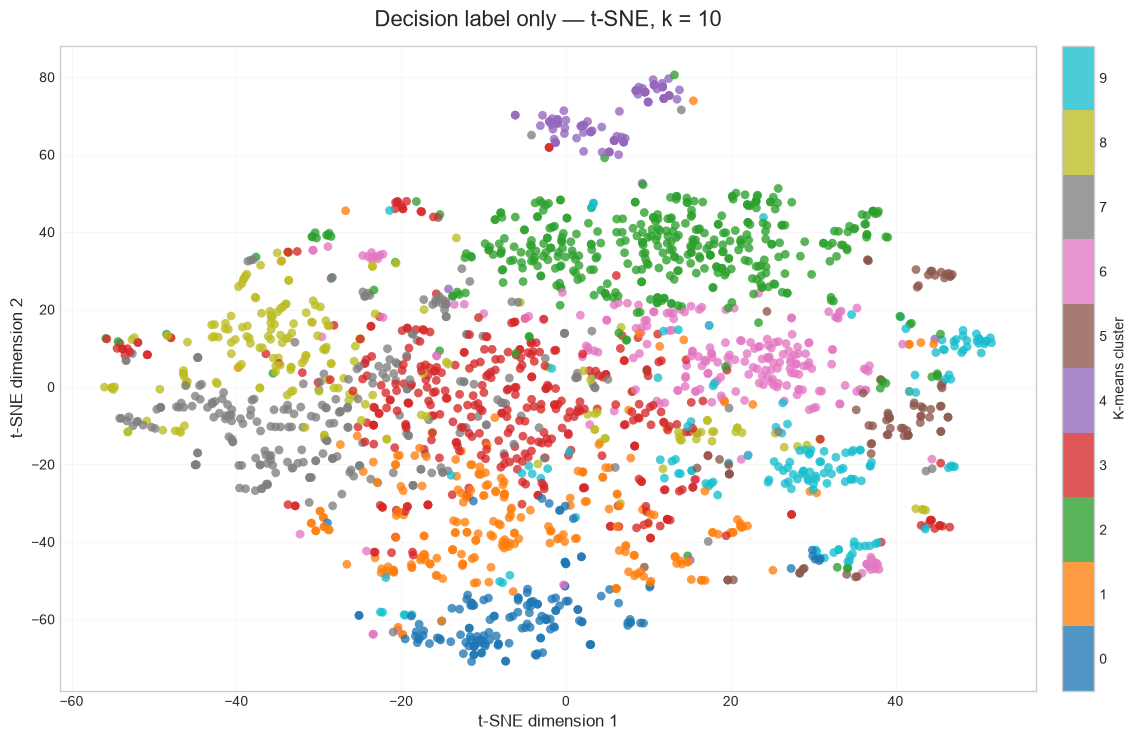

In [37]:
# Decision label only — t-SNE, k = 10
plot_single_projection(TSNE_POINTS['label_only'], 'label_only', 't-SNE', 10)


## UMAP cluster views

Each candidate cluster solution is displayed in a separate full-size output. The coordinates remain identical across k within the same representation, so the assignments can be compared directly.


### Decision label + summary


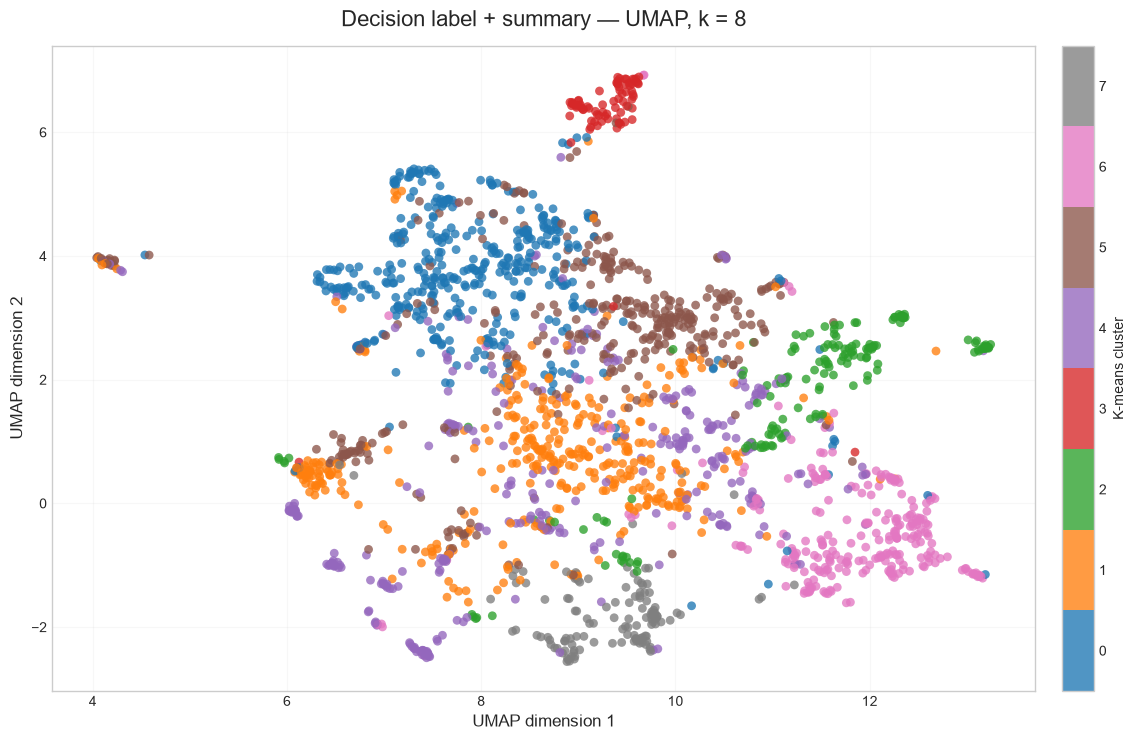

In [38]:
# Decision label + summary — UMAP, k = 8
plot_single_projection(UMAP_POINTS['label_summary'], 'label_summary', 'UMAP', 8)


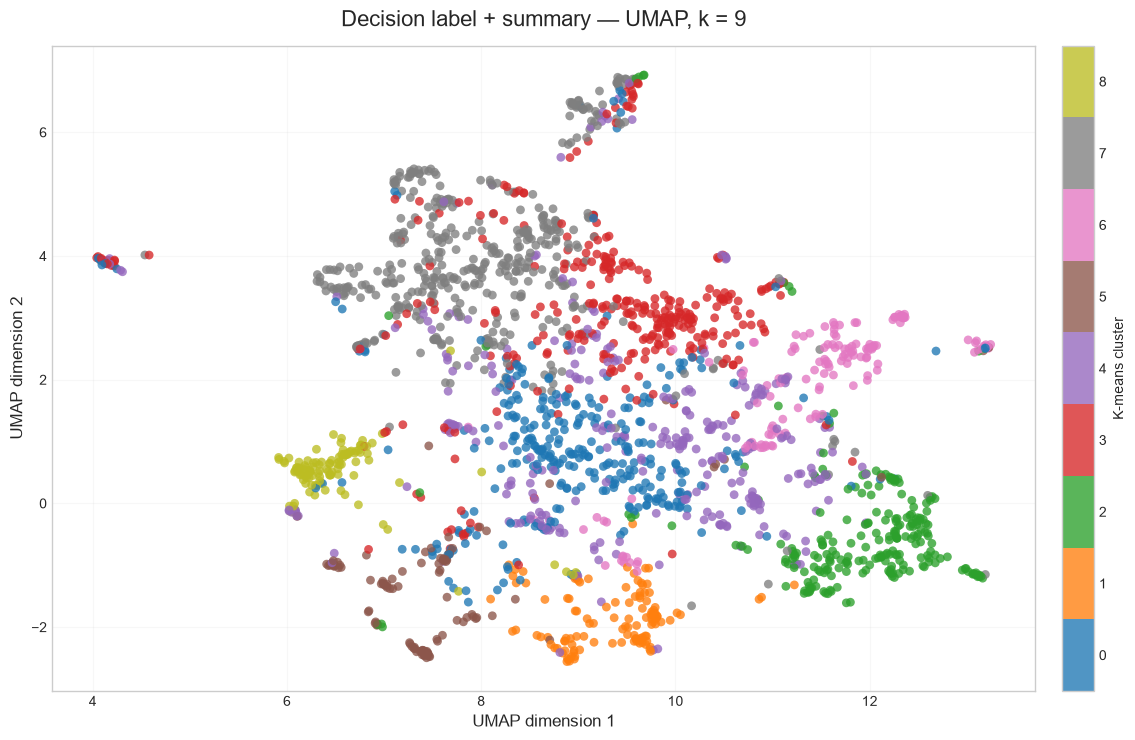

In [39]:
# Decision label + summary — UMAP, k = 9
plot_single_projection(UMAP_POINTS['label_summary'], 'label_summary', 'UMAP', 9)


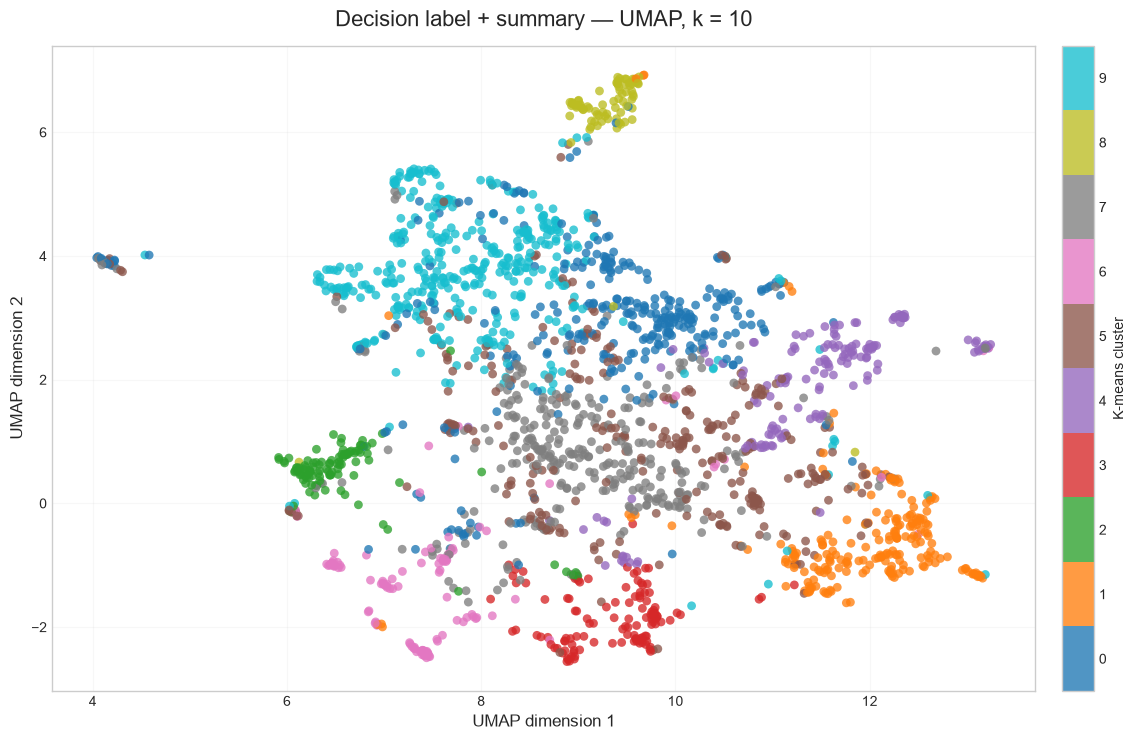

In [40]:
# Decision label + summary — UMAP, k = 10
plot_single_projection(UMAP_POINTS['label_summary'], 'label_summary', 'UMAP', 10)


### Decision label only


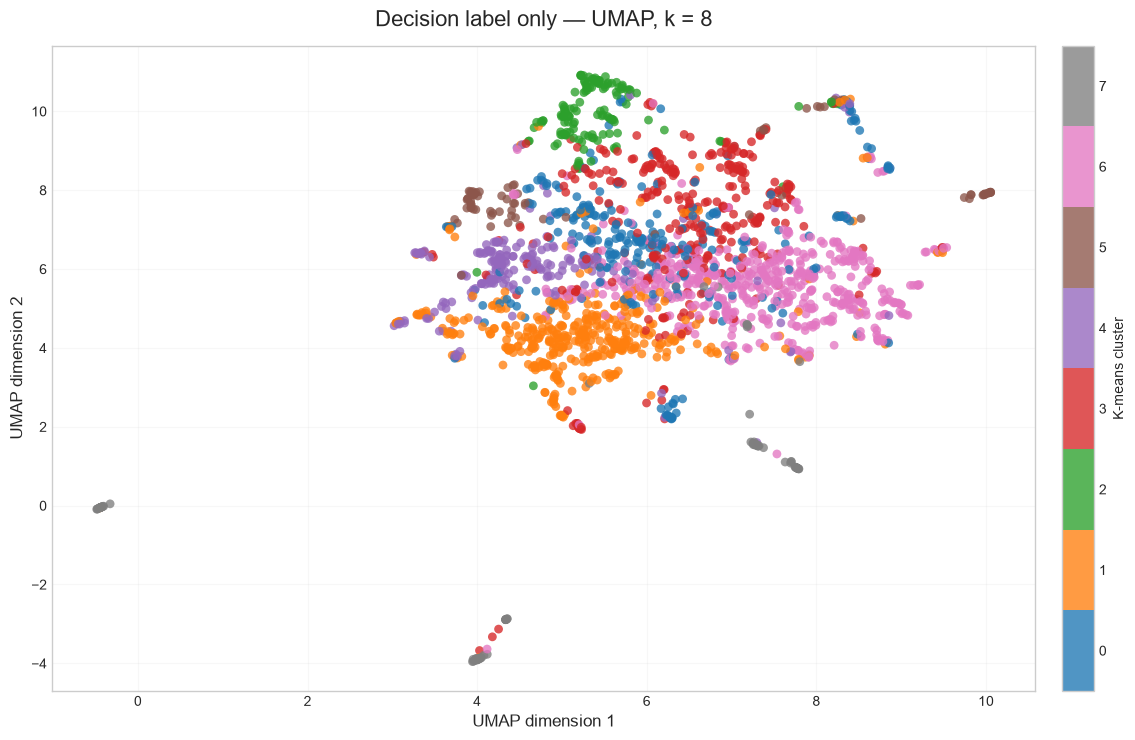

In [41]:
# Decision label only — UMAP, k = 8
plot_single_projection(UMAP_POINTS['label_only'], 'label_only', 'UMAP', 8)


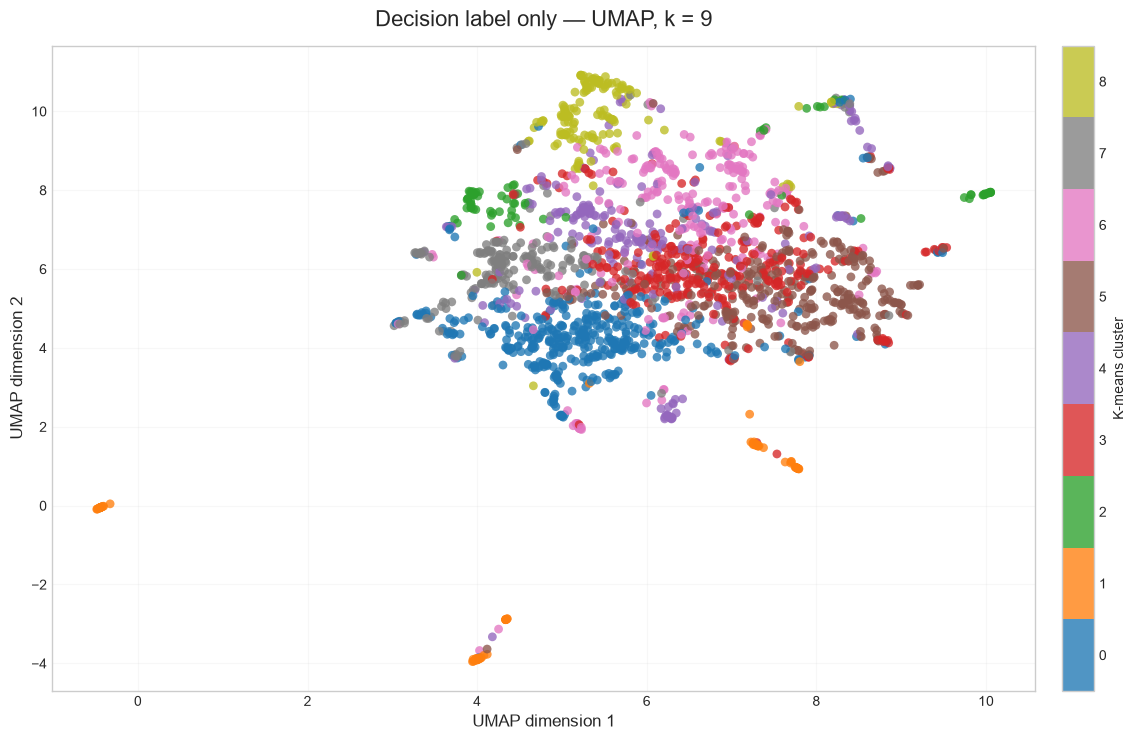

In [42]:
# Decision label only — UMAP, k = 9
plot_single_projection(UMAP_POINTS['label_only'], 'label_only', 'UMAP', 9)


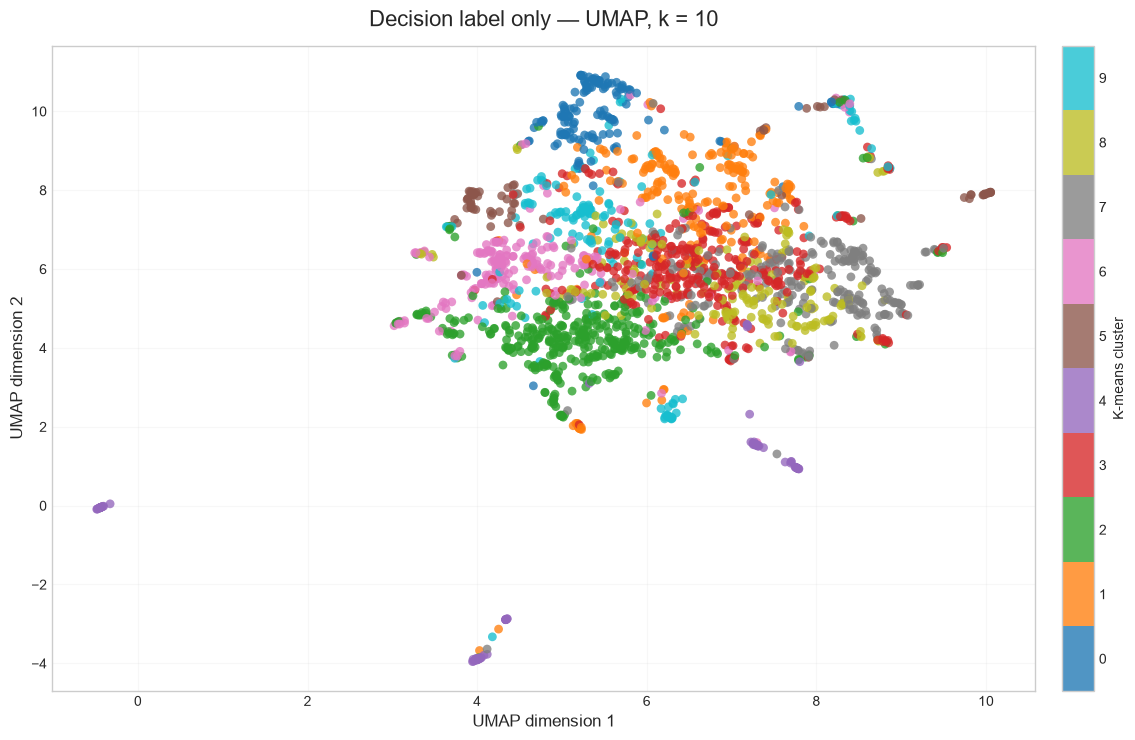

In [43]:
# Decision label only — UMAP, k = 10
plot_single_projection(UMAP_POINTS['label_only'], 'label_only', 'UMAP', 10)


## Cluster summaries and representative events

For every representation and focused k, the notebook saves cluster size, label diversity, task diversity, frequent labels, frequent tasks, and the eight events closest to each centroid. These records—not the projection plots alone—are used to judge semantic coherence and detect clusters dominated by one task family.


In [44]:
summary_tables = {}
for representation_name, config in REPRESENTATIONS.items():
    X = config['matrix']
    for k in FOCUS_K:
        model = models_by_representation[representation_name][k]
        cluster_column = f'{representation_name}_cluster_k{k}'
        working = assignments_df.copy()
        distances = model.transform(X)
        working['distance_to_centroid'] = distances[
            np.arange(len(working)), working[cluster_column].to_numpy(),
        ]
        summary_rows = []
        representative_parts = []
        for cluster_id, group in working.groupby(cluster_column, sort=True):
            frequent_labels = group['decision_type_label_normalized'].value_counts().head(10)
            frequent_tasks = group['task_id'].value_counts().head(5)
            largest_task_share = group['task_id'].value_counts(normalize=True).iloc[0]
            summary_rows.append({
                'cluster': int(cluster_id),
                'n_events': len(group),
                'n_trajectories': group['trajectory_id'].nunique(),
                'n_tasks': group['task_id'].nunique(),
                'unique_labels': group['decision_type_label_normalized'].nunique(),
                'largest_task_share': round(float(largest_task_share), 3),
                'top_labels': ' | '.join(
                    f'{label} ({count})' for label, count in frequent_labels.items()
                ),
                'top_tasks': ' | '.join(
                    f'{task} ({count})' for task, count in frequent_tasks.items()
                ),
            })
            representative_parts.append(group.nsmallest(8, 'distance_to_centroid'))
        summary_df = pd.DataFrame(summary_rows)
        representatives_df = pd.concat(representative_parts, ignore_index=True)
        summary_df.to_csv(
            OUTPUT_DIR / f'{representation_name}_cluster_summary_k{k}.csv', index=False,
        )
        representatives_df.to_csv(
            OUTPUT_DIR / f'{representation_name}_cluster_representatives_k{k}.csv', index=False,
        )
        summary_tables[(representation_name, k)] = summary_df
        print(f"{config['title']} — k = {k}")
        display(summary_df)


Decision label + summary — k = 8


,cluster,n_events,n_trajectories,n_tasks,unique_labels,largest_task_share,top_labels,top_tasks
0,0,421,137,45,399,0.074,transformer architecture reconstruction (4) | local model caching (4) | c extension calculation implementation (3) | native inference im...,terminal-bench/video-processing (31) | terminal-bench/tune-mjcf (27) | terminal-bench/winning-avg-corewars (24) | terminal-bench/bn-fit-...
1,1,381,208,68,327,0.045,verified task termination (9) | validated task termination (7) | task completion decision (5) | end to end deployment validation (4) | t...,terminal-bench/custom-memory-heap-crash (17) | terminal-bench/cobol-modernization (14) | terminal-bench/schemelike-metacircular-eval (14...
2,2,170,61,23,157,0.165,wordlist password cracking (3) | self signed certificate generation (3) | differential key recovery (2) | archive hash conversion (2) | ...,terminal-bench/password-recovery (28) | terminal-bench/crack-7z-hash (20) | terminal-bench/feal-linear-cryptanalysis (20) | terminal-ben...
3,3,79,13,4,75,0.405,sequence alignment refinement (2) | primer pair selection (2) | ordered fusion assembly (2) | gc constrained codon optimization (2) | ra...,terminal-bench/protein-assembly (32) | terminal-bench/dna-assembly (27) | terminal-bench/dna-insert (19) | terminal-bench/raman-fitting (1)
4,4,336,156,59,316,0.065,polyglot delimiter revision (3) | software emulation fallback (3) | mailing list creation (3) | vim macro transformation (3) | metacircu...,terminal-bench/mailman (22) | terminal-bench/break-filter-js-from-html (18) | terminal-bench/schemelike-metacircular-eval (17) | termina...
5,5,375,190,71,347,0.051,task completion confirmation (6) | output artifact verification (4) | task completion decision (4) | solution completion decision (3) | ...,terminal-bench/financial-document-processor (19) | terminal-bench/count-dataset-tokens (18) | terminal-bench/chess-best-move (15) | term...
6,6,272,144,53,231,0.088,dependency installation (5) | build dependency installation (4) | interpreter fallback selection (4) | build toolchain installation (3) ...,terminal-bench/compile-compcert (24) | terminal-bench/build-cython-ext (21) | terminal-bench/sqlite-with-gcov (16) | terminal-bench/pypi...
7,7,123,43,18,117,0.236,end to end deployment validation (2) | repository state investigation (2) | branch deployment mapping (2) | repository state reset (2) |...,terminal-bench/git-multibranch (29) | terminal-bench/fix-git (22) | terminal-bench/git-leak-recovery (22) | terminal-bench/configure-git...


Decision label + summary — k = 9


,cluster,n_events,n_trajectories,n_tasks,unique_labels,largest_task_share,top_labels,top_tasks
0,0,320,192,66,293,0.044,end to end deployment validation (4) | final artifact verification (3) | full suite verification (3) | build artifact verification (2) |...,terminal-bench/custom-memory-heap-crash (14) | terminal-bench/schemelike-metacircular-eval (13) | terminal-bench/cobol-modernization (12...
1,1,117,39,14,112,0.248,end to end deployment validation (2) | repository state investigation (2) | branch deployment mapping (2) | repository state reset (2) |...,terminal-bench/git-multibranch (29) | terminal-bench/git-leak-recovery (22) | terminal-bench/fix-git (21) | terminal-bench/configure-git...
2,2,244,138,52,205,0.090,dependency installation (5) | build dependency installation (4) | interpreter fallback selection (4) | build toolchain installation (3) ...,terminal-bench/compile-compcert (22) | terminal-bench/sqlite-with-gcov (15) | terminal-bench/pypi-server (15) | terminal-bench/build-cyt...
3,3,336,176,67,323,0.051,output artifact verification (4) | output completion verification (2) | priority based conflict resolution (2) | solution file verificat...,terminal-bench/count-dataset-tokens (17) | terminal-bench/financial-document-processor (17) | terminal-bench/chess-best-move (13) | term...
4,4,313,168,66,297,0.067,polyglot delimiter revision (3) | vim macro transformation (3) | metacircular evaluator architecture (3) | polyglot source construction ...,terminal-bench/break-filter-js-from-html (21) | terminal-bench/schemelike-metacircular-eval (19) | terminal-bench/polyglot-rust-c (14) |...
5,5,107,42,14,97,0.159,software emulation fallback (3) | mailing list creation (3) | service startup fallback (2) | ssh authentication configuration (2) | host...,terminal-bench/mailman (17) | terminal-bench/qemu-alpine-ssh (16) | terminal-bench/install-windows-3.11 (12) | terminal-bench/qemu-start...
6,6,150,56,20,140,0.173,wordlist password cracking (3) | differential key recovery (2) | archive hash conversion (2) | passworded archive extraction (2) | self ...,terminal-bench/password-recovery (26) | terminal-bench/crack-7z-hash (20) | terminal-bench/feal-linear-cryptanalysis (17) | terminal-ben...
7,7,461,145,47,435,0.069,transformer architecture reconstruction (4) | local model caching (4) | c extension calculation implementation (3) | native inference im...,terminal-bench/video-processing (32) | terminal-bench/protein-assembly (27) | terminal-bench/tune-mjcf (25) | terminal-bench/winning-avg...
8,8,109,100,58,55,0.092,task completion confirmation (12) | task completion decision (10) | verified task termination (10) | validated task termination (9) | su...,terminal-bench/cancel-async-tasks (10) | terminal-bench/feal-linear-cryptanalysis (4) | terminal-bench/make-mips-interpreter (4) | termi...


Decision label + summary — k = 10


...

,cluster,n_events,n_trajectories,n_tasks,unique_labels,largest_task_share,top_labels,top_tasks
0,0,279,171,74,261,0.047,temporary artifact cleanup (4) | polyglot delimiter revision (3) | vim macro transformation (3) | canonical schema mapping (2) | priorit...,terminal-bench/multi-source-data-merger (13) | terminal-bench/fix-git (12) | terminal-bench/regex-chess (12) | terminal-bench/db-wal-rec...
1,1,427,268,84,388,0.037,end to end deployment validation (6) | output artifact verification (4) | final artifact verification (3) | full suite verification (3) ...,terminal-bench/extract-elf (16) | terminal-bench/git-multibranch (11) | terminal-bench/nginx-request-logging (10) | terminal-bench/git-l...
2,2,148,100,38,120,0.074,dependency installation (5) | build dependency installation (4) | build toolchain installation (3) | system package installation fallbac...,terminal-bench/pypi-server (11) | terminal-bench/build-cython-ext (10) | terminal-bench/sqlite-with-gcov (9) | terminal-bench/mcmc-sampl...
3,3,340,179,67,301,0.059,interpreter fallback selection (4) | api compatibility (3) | c extension calculation implementation (3) | native inference implementatio...,terminal-bench/mailman (20) | terminal-bench/compile-compcert (15) | terminal-bench/qemu-alpine-ssh (14) | terminal-bench/configure-git-...
4,4,223,136,61,221,0.085,repository state investigation (2) | elf structure inspection (2) | fallback inspection method (1) | vulnerability classification (1) | ...,terminal-bench/break-filter-js-from-html (19) | terminal-bench/extract-elf (12) | terminal-bench/password-recovery (11) | terminal-bench...
5,5,82,47,17,71,0.171,wordlist password cracking (3) | self signed certificate generation (3) | differential key recovery (2) | passworded archive extraction ...,terminal-bench/crack-7z-hash (14) | terminal-bench/openssl-selfsigned-cert (14) | terminal-bench/git-multibranch (12) | terminal-bench/s...
6,6,565,215,72,536,0.051,transformer architecture reconstruction (4) | local model caching (4) | pgs solver selection (3) | meeting slot selection (3) | training...,terminal-bench/video-processing (29) | terminal-bench/winning-avg-corewars (26) | terminal-bench/protein-assembly (24) | terminal-bench/...
7,7,93,88,57,38,0.086,task completion confirmation (12) | task completion decision (10) | verified task termination (10) | validated task termination (9) | su...,terminal-bench/cancel-async-tasks (8) | terminal-bench/feal-linear-cryptanalysis (4) | terminal-bench/mteb-retrieve (3) | terminal-bench...


Decision label only — k = 9


,cluster,n_events,n_trajectories,n_tasks,unique_labels,largest_task_share,top_labels,top_tasks
0,0,413,263,84,376,0.034,end to end deployment validation (6) | output artifact verification (4) | final artifact verification (3) | full suite verification (3) ...,terminal-bench/extract-elf (14) | terminal-bench/nginx-request-logging (10) | terminal-bench/git-multibranch (10) | terminal-bench/git-l...
1,1,91,86,57,36,0.088,task completion confirmation (12) | task completion decision (10) | verified task termination (10) | validated task termination (9) | su...,terminal-bench/cancel-async-tasks (8) | terminal-bench/feal-linear-cryptanalysis (4) | terminal-bench/mteb-retrieve (3) | terminal-bench...
2,2,81,46,16,70,0.173,wordlist password cracking (3) | self signed certificate generation (3) | differential key recovery (2) | passworded archive extraction ...,terminal-bench/crack-7z-hash (14) | terminal-bench/openssl-selfsigned-cert (14) | terminal-bench/git-multibranch (12) | terminal-bench/s...
3,3,343,200,77,322,0.044,mailing list creation (3) | meeting slot selection (3) | version selection (2) | training configuration (2) | canonical schema mapping (...,terminal-bench/mteb-leaderboard (15) | terminal-bench/winning-avg-corewars (14) | terminal-bench/mailman (13) | terminal-bench/multi-sou...
4,4,230,149,73,215,0.048,temporary artifact cleanup (4) | polyglot delimiter revision (3) | vim macro transformation (3) | archive hash conversion (2) | reposito...,terminal-bench/git-multibranch (11) | terminal-bench/fix-git (10) | terminal-bench/regex-chess (10) | terminal-bench/db-wal-recovery (9)...
5,5,358,151,55,339,0.075,transformer architecture reconstruction (4) | local model caching (4) | pgs solver selection (3) | lorentzian peak fitting (2) | baselin...,terminal-bench/video-processing (27) | terminal-bench/tune-mjcf (18) | terminal-bench/protein-assembly (18) | terminal-bench/largest-eig...
6,6,269,156,59,238,0.052,interpreter fallback selection (4) | api compatibility (3) | c extension calculation implementation (3) | native inference implementatio...,terminal-bench/qemu-alpine-ssh (14) | terminal-bench/caffe-cifar-10 (11) | terminal-bench/headless-terminal (11) | terminal-bench/compil...
7,7,215,136,63,213,0.065,repository state investigation (2) | elf structure inspection (2) | fallback inspection method (1) | vulnerability classification (1) | ...,terminal-bench/break-filter-js-from-html (14) | terminal-bench/extract-elf (12) | terminal-bench/password-recovery (10) | terminal-bench...
8,8,157,103,38,127,0.070,dependency installation (5) | build dependency installation (4) | build toolchain installation (3) | system package installation fallbac...,terminal-bench/pypi-server (11) | terminal-bench/build-cython-ext (10) | terminal-bench/sqlite-with-gcov (9) | terminal-bench/configure-...


Decision label only — k = 10


,cluster,n_events,n_trajectories,n_tasks,unique_labels,largest_task_share,top_labels,top_tasks
0,0,151,102,38,122,0.073,dependency installation (5) | build dependency installation (4) | build toolchain installation (3) | system package installation fallbac...,terminal-bench/pypi-server (11) | terminal-bench/build-cython-ext (10) | terminal-bench/sqlite-with-gcov (9) | terminal-bench/mcmc-sampl...
1,1,232,136,50,204,0.060,interpreter fallback selection (4) | api compatibility (3) | local package server setup (3) | software emulation fallback (3) | metacirc...,terminal-bench/qemu-alpine-ssh (14) | terminal-bench/compile-compcert (11) | terminal-bench/git-multibranch (10) | terminal-bench/headle...
2,2,407,259,84,370,0.037,end to end deployment validation (6) | output artifact verification (4) | final artifact verification (3) | full suite verification (3) ...,terminal-bench/extract-elf (15) | terminal-bench/nginx-request-logging (10) | terminal-bench/mailman (10) | terminal-bench/reshard-c4-da...
3,3,372,203,76,348,0.040,polyglot delimiter revision (3) | mailing list creation (3) | vim macro transformation (3) | meeting slot selection (3) | version select...,terminal-bench/multi-source-data-merger (15) | terminal-bench/dna-assembly (15) | terminal-bench/mteb-leaderboard (13) | terminal-bench/...
4,4,91,86,57,36,0.088,task completion confirmation (12) | task completion decision (10) | verified task termination (10) | validated task termination (9) | su...,terminal-bench/cancel-async-tasks (8) | terminal-bench/feal-linear-cryptanalysis (4) | terminal-bench/mteb-retrieve (3) | terminal-bench...
5,5,78,42,17,68,0.179,wordlist password cracking (3) | self signed certificate generation (3) | passworded archive extraction (2) | ssh connectivity verificat...,terminal-bench/crack-7z-hash (14) | terminal-bench/openssl-selfsigned-cert (14) | terminal-bench/git-multibranch (12) | terminal-bench/s...
6,6,215,134,62,213,0.070,repository state investigation (2) | elf structure inspection (2) | fallback inspection method (1) | vulnerability classification (1) | ...,terminal-bench/break-filter-js-from-html (15) | terminal-bench/extract-elf (12) | terminal-bench/winning-avg-corewars (10) | terminal-be...
7,7,261,124,49,239,0.077,transformer architecture reconstruction (4) | local model caching (4) | c extension calculation implementation (3) | native inference im...,terminal-bench/winning-avg-corewars (20) | terminal-bench/tune-mjcf (18) | terminal-bench/train-fasttext (17) | terminal-bench/largest-e...
8,8,192,91,42,187,0.135,lorentzian peak fitting (2) | sequence alignment refinement (2) | test path correction (2) | ordered fusion assembly (2) | domain filter...,terminal-bench/video-processing (26) | terminal-bench/path-tracing (17) | terminal-bench/model-extraction-relu-logits (14) | terminal-be...
9,9,158,108,57,149,0.070,temporary artifact cleanup (4) | differential key recovery (2) | archive hash conversion (2) | repository state reset (2) | artifact cle...,terminal-bench/git-multibranch (11) | terminal-bench/git-leak-recovery (11) | terminal-bench/fix-git (10) | terminal-bench/db-wal-recove...


## Generated outputs

All generated files are written under `outputs/gpt_luna_light_v2/semantic_clustering/`:

- separate cached semantic embeddings for label-plus-summary and label-only;
- elbow and silhouette metrics for both representations;
- k = 8, 9, and 10 assignments for both representations;
- Adjusted Rand agreement between the representations;
- separate full-size PCA, t-SNE, and UMAP figures for every focused cluster solution;
- cluster summaries with task-diversity indicators; and
- centroid-nearest representative decision events.


## Interpretation order

1. Compare silhouette score, inertia, and cluster-size balance across candidate k values.
2. Check agreement between label-only and label-plus-summary partitions.
3. Inspect centroid-nearest events and frequent labels for semantic coherence.
4. Use `n_tasks` and `largest_task_share` to identify task-dominated clusters.
5. Compare PCA, t-SNE, and UMAP cautiously; visible separation alone is not evidence of a stable concept.
6. Treat clusters as provisional until quantitative separation and representative-event review agree.
